# Model 07: Net Profit Prediction
### College Data Mining & DWDM Laboratory Submission
**Algorithm:** Linear Regression  
**Problem Type:** Margin Regression Analysis  
**Key Concepts Demonstrated:**
- Syllabus-aligned algorithm implementation
- Data preprocessing & descriptive statistics
- Model training, hyperparameter tuning & evaluation
- Joblib model serialization and sample inference


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# Ensure parent directory is in path
sys.path.append(os.path.abspath(".."))
from preprocessing.preprocess import load_dataset, clean_and_impute

# Load and clean dataset
df = load_dataset()
df_clean = clean_and_impute(df)
print(f"Dataset ready: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns")
df_clean.head(3)


Dataset ready: 1000 rows, 30 columns


,date,day_of_week,is_weekend,product_name,category,price,discount,previous_day_sales,sales_7_day_average,sales_30_day_average,...,sales_90_day,turnover_rate,days_since_last_sale,category_label,inventory_status,business_activity,total_expense,expense_3_month_average,average_order_value,profit
0,2024-01-01,Monday,0,Laundry Detergent 1kg,Household,210.0,10.43,3599.34,3599.34,3599.34,...,205357.08,3.62,12,MEDIUM_DEMAND,RESTOCK,14.87,3044.67,3044.67,97.28,-275.43
1,2024-01-02,Tuesday,0,Basmati Rice 5kg,Grocery,450.0,2.96,3599.34,3656.81,3656.81,...,316258.19,3.77,1,MEDIUM_DEMAND,RESTOCK,15.39,3100.65,3072.66,95.24,-358.75
2,2024-01-03,Wednesday,0,Organic Honey 500g,Grocery,280.0,6.88,3714.28,3750.13,3750.13,...,159407.77,5.20,0,MEDIUM_DEMAND,RESTOCK,12.33,3445.75,3197.02,115.79,-448.90


In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

feature_cols = ["revenue", "total_expense", "invoice_count", "average_order_value"]
X = df_clean[feature_cols].values
y = df_clean["profit"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Profit Model Evaluation:")
print(f"  MAE:  Rs. {mean_absolute_error(y_test, y_pred):.2f}")
print(f"  RMSE: Rs. {root_mean_squared_error(y_test, y_pred):.2f}")
print(f"  R²:   {r2_score(y_test, y_pred):.4f}")


Profit Model Evaluation:
  MAE:  Rs. 54.05
  RMSE: Rs. 63.06
  R²:   0.9553


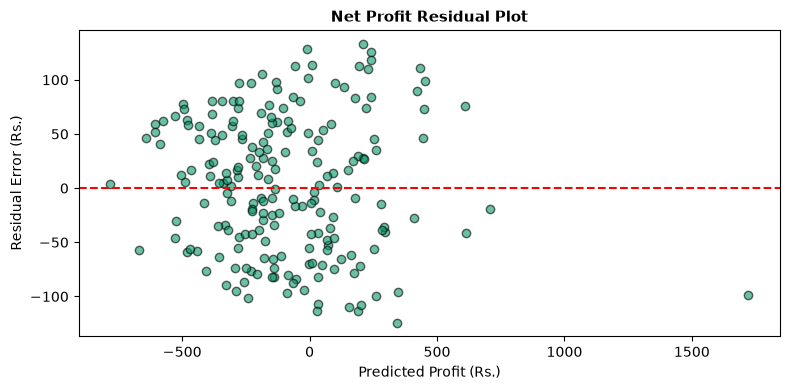

In [3]:
# Residual Plot
residuals = y_test - y_pred
plt.figure(figsize=(8, 4))
plt.scatter(y_pred, residuals, color='#059669', alpha=0.6, edgecolors='k')
plt.axhline(0, color='red', linestyle='--')
plt.title("Net Profit Residual Plot", fontsize=11, fontweight='bold')
plt.xlabel("Predicted Profit (Rs.)")
plt.ylabel("Residual Error (Rs.)")
plt.tight_layout()
plt.show()


In [4]:
# Joblib Save & Test
joblib.dump(model, "../models/profit_model.joblib")
del model
loaded_model = joblib.load("../models/profit_model.joblib")

sample = np.array([[120000.0, 70000.0, 350, 342.8]])
print(f"Predicted Net Profit: Rs. {loaded_model.predict(sample)[0]:.2f}")


Predicted Net Profit: Rs. 17491.78
